# Problem Statement

## **Business Context**

"Visit with Us," a leading travel company, is revolutionizing the tourism industry by leveraging data-driven strategies to optimize operations and customer engagement. While introducing a new package offering, such as the Wellness Tourism Package, the company faces challenges in targeting the right customers efficiently. The manual approach to identifying potential customers is inconsistent, time-consuming, and prone to errors, leading to missed opportunities and suboptimal campaign performance.

To address these issues, the company aims to implement a scalable and automated system that integrates customer data, predicts potential buyers, and enhances decision-making for marketing strategies. By utilizing an MLOps pipeline, the company seeks to achieve seamless integration of data preprocessing, model development, deployment, and CI/CD practices for continuous improvement. This system will ensure efficient targeting of customers, timely updates to the predictive model, and adaptation to evolving customer behaviors, ultimately driving growth and customer satisfaction.


## **Objective**

As an MLOps Engineer at "Visit with Us," your responsibility is to design and deploy an MLOps pipeline on GitHub to automate the end-to-end workflow for predicting customer purchases. The primary objective is to build a model that predicts whether a customer will purchase the newly introduced Wellness Tourism Package before contacting them. The pipeline will include data cleaning, preprocessing, transformation, model building, training, evaluation, and deployment, ensuring consistent performance and scalability. By leveraging GitHub Actions for CI/CD integration, the system will enable automated updates, streamline model deployment, and improve operational efficiency. This robust predictive solution will empower policymakers to make data-driven decisions, enhance marketing strategies, and effectively target potential customers, thereby driving customer acquisition and business growth.

## **Data Description**

The dataset contains customer and interaction data that serve as key attributes for predicting the likelihood of purchasing the Wellness Tourism Package. The detailed attributes are:

**Customer Details**
- **CustomerID:** Unique identifier for each customer.
- **ProdTaken:** Target variable indicating whether the customer has purchased a package (0: No, 1: Yes).
- **Age:** Age of the customer.
- **TypeofContact:** The method by which the customer was contacted (Company Invited or Self Inquiry).
- **CityTier:** The city category based on development, population, and living standards (Tier 1 > Tier 2 > Tier 3).
- **Occupation:** Customer's occupation (e.g., Salaried, Freelancer).
- **Gender:** Gender of the customer (Male, Female).
- **NumberOfPersonVisiting:** Total number of people accompanying the customer on the trip.
- **PreferredPropertyStar:** Preferred hotel rating by the customer.
- **MaritalStatus:** Marital status of the customer (Single, Married, Divorced).
- **NumberOfTrips:** Average number of trips the customer takes annually.
- **Passport:** Whether the customer holds a valid passport (0: No, 1: Yes).
- **OwnCar:** Whether the customer owns a car (0: No, 1: Yes).
- **NumberOfChildrenVisiting:** Number of children below age 5 accompanying the customer.
- **Designation:** Customer's designation in their current organization.
- **MonthlyIncome:** Gross monthly income of the customer.

**Customer Interaction Data**
- **PitchSatisfactionScore:** Score indicating the customer's satisfaction with the sales pitch.
- **ProductPitched:** The type of product pitched to the customer.
- **NumberOfFollowups:** Total number of follow-ups by the salesperson after the sales pitch.-
- **DurationOfPitch:** Duration of the sales pitch delivered to the customer.


## Pre-requisites

This project deploys everything on **GitHub Actions** (the ML pipeline) and **Streamlit Community Cloud** (the live app). No Hugging Face and no Codespaces are used.

**1. Create a Personal Access Token (PAT)**
- GitHub → **Settings** → **Developer settings** → **Personal access tokens** → **Tokens (classic)**
- **Generate new token (classic)** and enable these scopes:
  - `repo` &nbsp;(push code + let the pipeline commit the trained model back)
  - `workflow` &nbsp;(push the Actions workflow file)
- Copy the token.

**2. Store the token in Colab secrets**
- In Colab, click the **key icon** (left sidebar) → **Add new secret**
- Name: **GH_TOKEN** &nbsp;(must match `COLAB_SECRET_NAME` in the config cell below)
- Value: paste your token, and toggle **Notebook access** on.

**3. Create a Streamlit Community Cloud account**
- Go to **https://share.streamlit.io** and sign in with the **same GitHub account** so it can access your repo. You'll deploy the app from there at the very end (see the last section).

**4. Get an ngrok authtoken (for local MLflow experimentation)**
- Go to **https://dashboard.ngrok.com/authtokens**, sign up/sign in, and copy your authtoken.
- Store it as a second Colab secret named **NGROK_TOKEN** (key icon → **Add new secret**, toggle **Notebook access** on). The **Experimentation and Tracking (Development Environment)** section reads it with `userdata.get("NGROK_TOKEN")` to expose the MLflow UI.

## Running Locally (outside Colab)
The notebook runs in Google Colab or in a local Jupyter kernel. The cell below sets `IN_COLAB`, and the few Colab-specific cells branch on it:
- **Dependencies:** Colab installs them with `pip` in the next section. Locally they are installed once in a Python 3.11 virtual environment (`.venv`), see the note after the install cell.
- **GitHub token:** Colab reads the `GH_TOKEN` secret. Locally the token is read from the `GH_TOKEN` environment variable if it is set; otherwise from a `.env` file next to this notebook containing one line `GH_TOKEN=<your GitHub token>`. The `.env` file is the recommended option when running the notebook from the Kiro / VS Code kernel, because that kernel does not inherit variables exported in your shell. `.env` is listed in the repository's `.gitignore` and the push cell only uploads `tourism_project/` and `.github/`, so it is never pushed. The notebook never prints the token.
- **Dataset:** locally `./tourism.csv` (next to this notebook) is copied into `tourism_project/data/`.
- **MLflow UI:** locally it is served on http://127.0.0.1:5001 without ngrok (port 5000 is held by the macOS AirPlay Receiver) and is stopped in the last section.
- **Working directory:** the folder that contains this notebook and `tourism.csv` plays the role of Colab's `/content`.

Run everything top to bottom from that folder:
```bash
source .venv/bin/activate
export GH_TOKEN=<your GitHub token>   # not needed if a .env file is present
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=1800 \
    --ExecutePreprocessor.kernel_name=python3 Learner_Template_Notebook_AML_and_MLOps_Project.ipynb
```
(or start `jupyter lab` from the same shell and use **Run All**).

When using the IDE kernel instead, create the `.env` file once:

```bash
printf 'GH_TOKEN=%s\n' '<your GitHub token>' > .env && chmod 600 .env
```

then select the `.venv` interpreter as the kernel and run the cells top to bottom.

In [15]:
# Detect whether the notebook runs in Google Colab or locally
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Google Colab" if IN_COLAB else "Running locally (not in Colab)")

Running locally (not in Colab)


##Installing and Importing Necessary Libraries

In [16]:
# Colab only. Locally these packages are already installed in the venv (see the note below).
if IN_COLAB:
    !pip install -q PyGithub==2.9.1
    !pip install mlflow==3.0.1 pyngrok==7.2.12 -q
else:
    print("Local run: using the packages installed in the virtual environment.")

Local run: using the packages installed in the virtual environment.


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

**Local run:** the install cell above is skipped (`IN_COLAB` is `False`), so no kernel restart is needed. The pinned dependencies are installed once in a Python 3.11 virtual environment before starting Jupyter:
```bash
python3.11 -m venv .venv
source .venv/bin/activate
pip install scikit-learn==1.5.1 xgboost==2.1.1 pandas==2.2.2 numpy==1.26.4 joblib==1.4.2 mlflow==3.0.1 \
            PyGithub==2.9.1 pyngrok==7.2.12 ipykernel nbconvert nbclient jupyter
pip check
```

In [17]:
import os
from github import Github, GithubException

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
import joblib
import mlflow

## Configuration

In [18]:
# Edit these three values, then run every cell top to bottom.
GITHUB_USERNAME   = "ravi-stiwari"                # Your GitHub username
REPO_NAME         = "tourism-package-prediction"  # Repository name (will be created if it does not exist)
COLAB_SECRET_NAME = "GH_TOKEN"                     # Name of the secret stored in Colab (key icon on the left)

REPO   = f"{GITHUB_USERNAME}/{REPO_NAME}"
BRANCH = "main"

print("Target repository:", REPO)
print("Branch           :", BRANCH)


Target repository: ravi-stiwari/tourism-package-prediction
Branch           : main


### Secrets in Colab

**Secrets** in Google Colab provide a secure way to store sensitive information such as API keys, access tokens, and passwords. Instead of hardcoding these values in your notebook, you can save them as secrets and access them securely whenever needed.

1. In the left pane of Google Colab, click the fifth icon, which looks like a key.

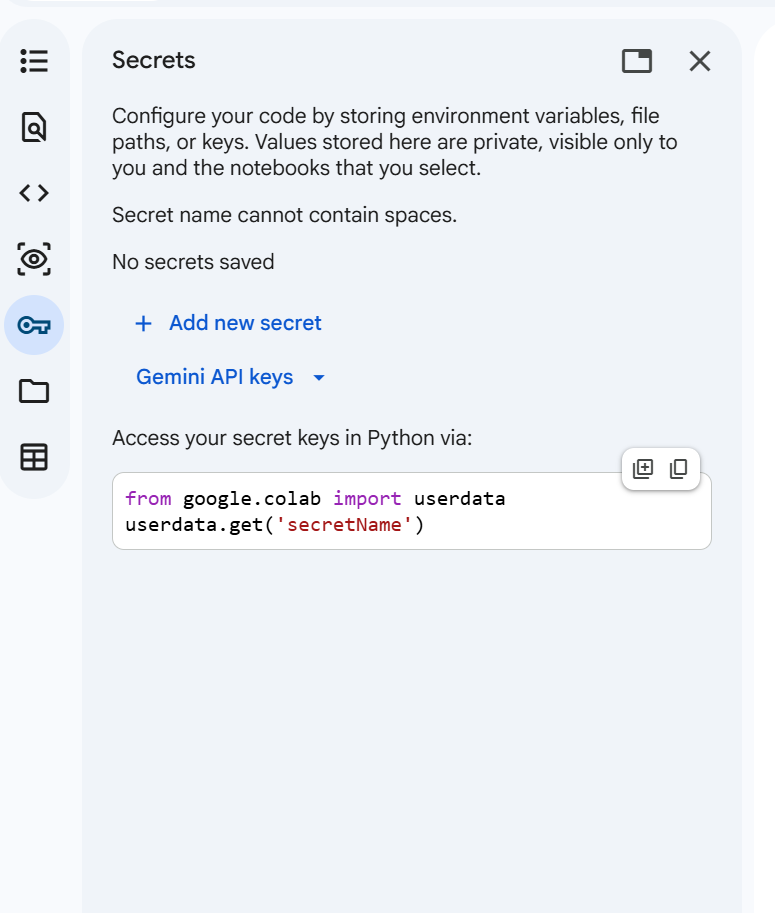

2. Then, click **+ Add new secret**. In the **Name** field, enter a name to identify the GitHub Personal Access Token, for example, **GH_TOKEN**. In the **Value** field, paste the token. Once done, close the **Secrets** window. We will access this token programmatically later.

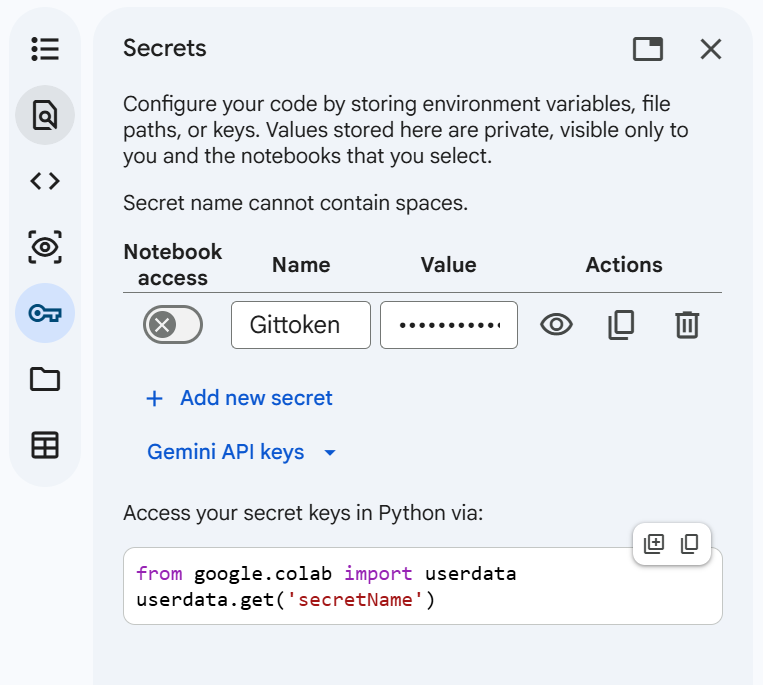

In [19]:
# Make the token available to both PyGithub and the gh CLI
# Colab: read it from the Colab secret.
# Local run: use the GH_TOKEN environment variable if set, otherwise read it from a .env file
# (the IDE / VS Code kernel does not inherit variables exported in your shell).
import os

def _load_env_file(path):
    """Minimal KEY=VALUE parser (no python-dotenv needed). Returns the GH_TOKEN value or None."""
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            key, value = line.split("=", 1)
            key, value = key.strip(), value.strip().strip('"').strip("'")
            if key == "GH_TOKEN" and value:
                return value
    return None

if IN_COLAB:
    from google.colab import userdata

    os.environ["GH_TOKEN"] = userdata.get(COLAB_SECRET_NAME)
    token_source = f"Colab secret {COLAB_SECRET_NAME}"
elif os.environ.get("GH_TOKEN"):
    token_source = "GH_TOKEN environment variable"
else:
    token_source = None
    for env_path in ("TourismPackagePrediction/.env", os.path.join("..", ".env")):
        if os.path.isfile(env_path):
            token = _load_env_file(env_path)
            if token:
                os.environ["GH_TOKEN"] = token
                token_source = f".env file ({os.path.abspath(env_path)})"
                break
    if token_source is None:
        raise RuntimeError(
            "GH_TOKEN is not set. Either create a file named .env next to this notebook "
            "containing a single line  GH_TOKEN=<your GitHub token>  and re-run this cell, "
            "or export GH_TOKEN in the shell before starting Jupyter and restart the kernel."
        )

print("Token loaded.")
print("Source:", token_source)


Token loaded.
Source: GH_TOKEN environment variable


# Model Building

In [20]:
# Create a master folder to keep all files created when executing the below code cells
import os
os.makedirs("tourism_project", exist_ok=True)

In [21]:
# Create a folder for storing the model building files
os.makedirs("tourism_project/model_building", exist_ok=True)

## Data Registration

In [22]:
os.makedirs("tourism_project/data", exist_ok=True)

Once the **data** folder created after executing the above cell, please upload the **tourism.csv** in to the folder

In [23]:
# Colab: upload tourism.csv into tourism_project/data/ with the file browser (see above).
# Local run: copy ./tourism.csv (next to this notebook) into tourism_project/data/.
import shutil

DATA_CSV = "tourism_project/data/tourism.csv"
if os.path.exists(DATA_CSV):
    print("Dataset found:", DATA_CSV)
elif not IN_COLAB:
    shutil.copy("TourismPackagePrediction/tourism.csv", DATA_CSV)
    print("Copied ./tourism.csv to", DATA_CSV)
else:
    print("Upload tourism.csv into tourism_project/data/ before running the next cells.")

Copied ./tourism.csv to tourism_project/data/tourism.csv


Register the dataset with a small script (for example `tourism_project/model_building/data_register.py`) that reads this CSV from the repo, checks that the expected columns are present, and prints a short summary. The dataset stays inside the GitHub repo, so no external dataset store is needed.

In [24]:
%%writefile tourism_project/model_building/data_register.py
"""
Data registration step.

The dataset lives inside the GitHub repository (tourism_project/data/), so no
external data store is needed. This script "registers" it by validating that
the expected columns are present and printing a short summary that the pipeline
log captures.
"""
import os
import sys
import pandas as pd

DATA_PATH = "tourism_project/data/tourism.csv"

EXPECTED_COLUMNS = {
    "ProdTaken",
    "Age",
    "TypeofContact",
    "CityTier",
    "DurationOfPitch",
    "Occupation",
    "Gender",
    "NumberOfPersonVisiting",
    "NumberOfFollowups",
    "ProductPitched",
    "PreferredPropertyStar",
    "MaritalStatus",
    "NumberOfTrips",
    "Passport",
    "PitchSatisfactionScore",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "Designation",
    "MonthlyIncome",
}


def main():
    if not os.path.exists(DATA_PATH):
        print(f"ERROR: dataset not found at {DATA_PATH}")
        sys.exit(1)

    df = pd.read_csv(DATA_PATH)
    columns = set(df.columns)

    missing = EXPECTED_COLUMNS - columns
    if missing:
        print("ERROR: the dataset is missing expected columns:", sorted(missing))
        sys.exit(1)

    print("Dataset registered successfully.")
    print("Path    :", DATA_PATH)
    print("Shape   :", df.shape)
    print("Columns :", list(df.columns))
    print("\nTarget distribution (ProdTaken):")
    print(df["ProdTaken"].value_counts())
    print("\nMissing values per column:")
    print(df.isnull().sum())


if __name__ == "__main__":
    main()


Writing tourism_project/model_building/data_register.py


In [25]:
!python tourism_project/model_building/data_register.py

Dataset registered successfully.
Path    : tourism_project/data/tourism.csv
Shape   : (4128, 21)
Columns : ['Unnamed: 0', 'CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome']

Target distribution (ProdTaken):
ProdTaken
0    3331
1     797
Name: count, dtype: int64

Missing values per column:
Unnamed: 0                  0
CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
Nu

## Data Preparation

In the cell below, write a script (for example `tourism_project/model_building/prep.py`) that:
- loads the dataset from the repository data folder,
- removes any unnecessary columns,
- splits the data into training and testing sets and saves them locally as CSV files.

The workflow passes these split files to the next job as an artifact, so there is no need to upload them anywhere.

In [26]:
%%writefile tourism_project/model_building/prep.py
"""
Data preparation step.

- Loads the registered dataset from the repository data folder.
- Cleans the data (fixes the "Fe Male" typo, drops identifier/index columns,
  imputes missing values as a safeguard).
- Splits the cleaned data into stratified train/test sets.
- Saves Xtrain/Xtest/ytrain/ytest as CSV files so the next pipeline job can
  pick them up as a workflow artifact.
"""
import os
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_PATH = "tourism_project/data/tourism.csv"
TARGET = "ProdTaken"


def load_data(path=DATA_PATH):
    df = pd.read_csv(path)
    print(f"Loaded data from {path} with shape {df.shape}")
    return df


def clean_data(df):
    # Drop the unnamed leading column (empty header; it is a row index that
    # equals CustomerID - 200000 in tourism.csv).
    unnamed = [c for c in df.columns if c.lower().startswith("unnamed")]
    df = df.drop(columns=unnamed, errors="ignore")

    # CustomerID is a unique identifier and carries no predictive signal.
    df = df.drop(columns=["CustomerID"], errors="ignore")

    # Fix the "Fe Male" data-entry typo of the existing "Female" label.
    # Other categories (e.g. MaritalStatus "Unmarried" vs "Single") are kept
    # exactly as they appear in the data.
    if "Gender" in df.columns:
        df["Gender"] = df["Gender"].replace({"Fe Male": "Female"})

    # Impute missing values (median for numeric, mode for categorical).
    # Safeguard only: tourism.csv has no missing values, so nothing changes.
    print("Missing values before imputation:", int(df.isnull().sum().sum()))
    num_cols = df.select_dtypes(include=["number"]).columns
    cat_cols = df.select_dtypes(exclude=["number"]).columns
    for c in num_cols:
        if df[c].isnull().any():
            df[c] = df[c].fillna(df[c].median())
    for c in cat_cols:
        if df[c].isnull().any():
            df[c] = df[c].fillna(df[c].mode()[0])

    print("After cleaning:", df.shape)
    print("Remaining missing values:", int(df.isnull().sum().sum()))
    return df


def main():
    df = load_data()
    df = clean_data(df)

    X = df.drop(columns=[TARGET])
    y = df[TARGET]

    Xtrain, Xtest, ytrain, ytest = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Save the splits at the repo root so the next job can consume them as an
    # uploaded artifact (matches the paths in .github/workflows/pipeline.yml).
    Xtrain.to_csv("Xtrain.csv", index=False)
    Xtest.to_csv("Xtest.csv", index=False)
    ytrain.to_csv("ytrain.csv", index=False)
    ytest.to_csv("ytest.csv", index=False)

    print("Saved Xtrain.csv, Xtest.csv, ytrain.csv, ytest.csv")
    print("Train shape:", Xtrain.shape, "Test shape:", Xtest.shape)


if __name__ == "__main__":
    main()


Writing tourism_project/model_building/prep.py


In [27]:
!python tourism_project/model_building/prep.py

Loaded data from tourism_project/data/tourism.csv with shape (4128, 21)
Missing values before imputation: 0
After cleaning: (4128, 19)
Remaining missing values: 0
Saved Xtrain.csv, Xtest.csv, ytrain.csv, ytest.csv
Train shape: (3302, 18) Test shape: (826, 18)


**Observations:**
- `tourism.csv` has 4,128 rows and 21 columns. The leading unnamed column (empty header) is a row index equal to `CustomerID − 200000`, and `CustomerID` has 4,128 unique values (one per row), so both are dropped as identifiers. That leaves 18 features plus the target.
- `Gender` contains 155 rows with `"Fe Male"`, a typo of the existing `"Female"` label, so they are mapped to `"Female"` (1,510 + 155 = 1,665 Female rows).
- `MaritalStatus` is kept as recorded: Married 1,990, Divorced 789, Unmarried 682, Single 667. `"Unmarried"` and `"Single"` are not merged, because the data does not show they mean the same thing, and their purchase rates differ (Unmarried 166/682 = 24.3%, Single 243/667 = 36.4%).
- `Occupation` = `"Free Lancer"` occurs in only 2 of 4,128 rows (both with `ProdTaken` = 1). With this split both rows fall in the training set, so the test metrics say nothing about this category.
- The dataset has 0 missing values, so the median/mode imputation is only a safeguard and changes nothing here (the script prints the count before and after).
- The target is imbalanced: 797 of 4,128 customers bought a package (19.3%). The 80/20 split is stratified on `ProdTaken`, giving 3,302 training rows (638 buyers, 19.3%) and 826 test rows (159 buyers, 19.2%). The four split files are saved at the repo root so the next workflow job can pick them up as an artifact.

## Experimentation and Tracking (Development Environment)

Before training, start the MLflow UI in the background and expose it through ngrok so every run logged by `train.py` can be browsed from a public URL.
- `train.py` does not set a tracking URI, so MLflow writes to its default store `./mlruns` under the current working directory (`/content` in Colab).
- `mlflow ui --port 5000` started from the same directory serves that same `./mlruns` store, so the training runs (the parent run and one nested run per grid candidate) appear in the UI.
- The ngrok authtoken is read from the Colab secret **NGROK_TOKEN** (see Pre-requisites step 4).
- **Local run:** ngrok is not used. The UI is started with `mlflow ui --host 127.0.0.1 --port 5001` and is available at http://127.0.0.1:5001 (port 5000 is held by the macOS AirPlay Receiver). The last section of the notebook stops this background server.

In [28]:
# Start the MLflow UI in the background.
# Colab: port 5000, exposed with ngrok.
# Local: port 5001 on http://127.0.0.1 (no ngrok; macOS AirPlay Receiver holds port 5000).
import subprocess
import sys
import time
import urllib.request

MLFLOW_PORT = 5000 if IN_COLAB else 5001
MLFLOW_UI_URL = f"http://127.0.0.1:{MLFLOW_PORT}"

# Serves ./mlruns, the same store train.py logs to (default tracking URI)
mlflow_ui = subprocess.Popen(
    [sys.executable, "-m", "mlflow", "ui", "--host", "127.0.0.1", "--port", str(MLFLOW_PORT)],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
    start_new_session=True,  # own process group, so it can be stopped as a whole later
)

# Wait (up to 60 s) until the server answers, without blocking the rest of the notebook
for _ in range(60):
    if mlflow_ui.poll() is not None:
        raise RuntimeError(f"MLflow UI exited early (is port {MLFLOW_PORT} already in use?)")
    try:
        urllib.request.urlopen(MLFLOW_UI_URL, timeout=2)
        break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError(f"MLflow UI did not start on {MLFLOW_UI_URL}")

print("MLflow tracking URI used by train.py:", mlflow.get_tracking_uri())
if IN_COLAB:
    from pyngrok import ngrok
    from google.colab import userdata

    ngrok.set_auth_token(userdata.get("NGROK_TOKEN"))
    public_url = ngrok.connect(MLFLOW_PORT).public_url
    print("MLflow UI:", public_url)
else:
    print("MLflow UI:", MLFLOW_UI_URL)

MLflow tracking URI used by train.py: file:///Users/ravishankertiwari/Downloads/study/mlruns
MLflow UI: http://127.0.0.1:5001


## Model Training and Registration with Experimentation Tracking

In the cell below, write a script (for example `tourism_project/model_building/train.py`) that:
- loads the train and test splits produced by the previous job,
- defines the model and a hyperparameter grid, and tunes it,
- logs the parameters and metrics to MLflow for experiment tracking,
- evaluates the best model,
- saves the best model into `tourism_project/deployment/` so the workflow can commit it into the repo.

In [29]:
%%writefile tourism_project/model_building/train.py
"""
Model building + experiment tracking step.

- Loads the train/test splits produced by the data-prep job.
- Builds a preprocessing + XGBoost pipeline.
- Tunes hyperparameters with GridSearchCV.
- Logs every grid candidate (nested runs) and the best parameters/metrics to MLflow.
- Evaluates the best model and saves it to tourism_project/deployment/ so the
  workflow can commit it back into the repository.
"""
import os
import joblib
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
import xgboost as xgb

DEPLOY_DIR = "tourism_project/deployment"
MODEL_PATH = os.path.join(DEPLOY_DIR, "best_tourism_model.joblib")


def load_splits():
    Xtrain = pd.read_csv("Xtrain.csv")
    Xtest = pd.read_csv("Xtest.csv")
    ytrain = pd.read_csv("ytrain.csv").squeeze("columns")
    ytest = pd.read_csv("ytest.csv").squeeze("columns")
    print("Loaded splits:", Xtrain.shape, Xtest.shape)
    return Xtrain, Xtest, ytrain, ytest


def build_pipeline(Xtrain):
    numeric_features = Xtrain.select_dtypes(include=["number"]).columns.tolist()
    categorical_features = Xtrain.select_dtypes(exclude=["number"]).columns.tolist()
    print("Numeric features     :", numeric_features)
    print("Categorical features :", categorical_features)

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ]
    )

    model = xgb.XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
    )

    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    return pipe


def main():
    os.makedirs(DEPLOY_DIR, exist_ok=True)

    Xtrain, Xtest, ytrain, ytest = load_splits()
    pipe = build_pipeline(Xtrain)

    # Handle class imbalance by weighting the positive class.
    neg, pos = (ytrain == 0).sum(), (ytrain == 1).sum()
    scale_pos_weight = float(neg) / float(pos) if pos else 1.0

    param_grid = {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__scale_pos_weight": [scale_pos_weight],
    }

    mlflow.set_experiment("tourism-package-prediction")

    with mlflow.start_run(run_name="xgboost_gridsearch"):
        grid = GridSearchCV(
            pipe,
            param_grid=param_grid,
            cv=5,
            scoring="f1",
            n_jobs=-1,
            verbose=1,
        )
        grid.fit(Xtrain, ytrain)

        best_model = grid.best_estimator_
        print("Best parameters:", grid.best_params_)

        # Log every grid candidate as a nested run (its parameters plus the
        # mean/std cross-validated F1), so all tuned combinations are tracked.
        results = grid.cv_results_
        for i, params in enumerate(results["params"]):
            with mlflow.start_run(run_name=f"candidate_{i}", nested=True):
                mlflow.log_params(params)
                mlflow.log_metric("mean_cv_f1", float(results["mean_test_score"][i]))
                mlflow.log_metric("std_cv_f1", float(results["std_test_score"][i]))
                mlflow.log_metric("rank_cv_f1", int(results["rank_test_score"][i]))
        print(f"Logged {len(results['params'])} grid candidates as nested MLflow runs.")
        # Log the best parameters and CV score in the parent run.
        mlflow.log_params(grid.best_params_)
        mlflow.log_metric("best_cv_f1", float(grid.best_score_))
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("scoring", "f1")

        # Evaluate on the held-out test set.
        ypred = best_model.predict(Xtest)
        yproba = best_model.predict_proba(Xtest)[:, 1]

        metrics = {
            "accuracy": accuracy_score(ytest, ypred),
            "precision": precision_score(ytest, ypred, zero_division=0),
            "recall": recall_score(ytest, ypred, zero_division=0),
            "f1": f1_score(ytest, ypred, zero_division=0),
            "roc_auc": roc_auc_score(ytest, yproba),
        }
        mlflow.log_metrics(metrics)

        print("\nTest-set performance:")
        for k, v in metrics.items():
            print(f"  {k}: {v:.4f}")
        print("\nClassification report:\n", classification_report(ytest, ypred))

        # Save the best model for deployment and log it to MLflow.
        joblib.dump(best_model, MODEL_PATH)
        print("Saved best model to", MODEL_PATH)
        # Input example (integer columns cast to float64 so the inferred
        # signature tolerates missing values) also records a model signature.
        int_cols = Xtrain.select_dtypes(include=["integer"]).columns
        input_example = Xtrain.head(5).astype({c: "float64" for c in int_cols})
        mlflow.sklearn.log_model(
            best_model, name="model", input_example=input_example
        )


if __name__ == "__main__":
    main()


Writing tourism_project/model_building/train.py


In [30]:
!python tourism_project/model_building/train.py

Loaded splits: (3302, 18) (826, 18)
Numeric features     : ['Age', 'CityTier', 'DurationOfPitch', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'MonthlyIncome']
Categorical features : ['TypeofContact', 'Occupation', 'Gender', 'ProductPitched', 'MaritalStatus', 'Designation']
2026/10/25 22:57:54 INFO mlflow.tracking.fluent: Experiment with name 'tourism-package-prediction' does not exist. Creating a new experiment.
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200, 'model__scale_pos_weight': 4.175548589341693, 'model__subsample': 0.8}
Logged 16 grid candidates as nested MLflow runs.

Test-set performance:
  accuracy: 0.9116
  precision: 0.7622
  recall: 0.7862
  f1: 0.7740
  roc_auc: 0.9501

Classification report:
               precision    recall  f1-score   sup

**Observations:**
- The training script builds an end-to-end `Pipeline` (scaling for numeric features + one-hot encoding for categorical features + an `XGBClassifier`), so the exact same preprocessing is applied at training and at inference time in the Streamlit app.
- The target is imbalanced: the training split has 2,664 non-buyers and 638 buyers (19.3% positive). `scale_pos_weight` is set to 2,664 / 638 = 4.1755 and the grid is scored on **F1** rather than plain accuracy.
- `GridSearchCV` (5 folds × 16 candidates = 80 fits) logs every candidate as a nested MLflow run (its parameters plus mean/std CV F1 and rank), and the parent run holds the best parameters, the best CV F1 and the test metrics.
- The best fitted pipeline is saved to `tourism_project/deployment/best_tourism_model.joblib`, which the workflow then commits back to the repository. It is also logged to MLflow with an input example and signature.

**Local run** (this executed notebook: Python 3.11.15 on macOS, `.venv` with the pinned packages; printed by the `train.py` cell above):
- Best parameters: `learning_rate=0.1`, `max_depth=5`, `n_estimators=200`, `subsample=0.8`, `scale_pos_weight=4.1755`. Best mean CV F1 = 0.7606 (std 0.0413).
- Test set (826 rows, 159 buyers): accuracy 0.9116, precision 0.7622, recall 0.7862, F1 0.7740, ROC-AUC 0.9501.
- `mlflow.search_runs` on the local `./mlruns` returned 17 runs in the `tourism-package-prediction` experiment: 1 parent and 16 nested candidate runs (top-ranked `candidate_14`).

**CI runs** (GitHub Actions, `model-traning` job log, same pinned `tourism_project/requirements.txt`):
- Run [40210506669](https://github.com/ravi-stiwari/tourism-package-prediction/actions/runs/40210506669) and run [40212324392](https://github.com/ravi-stiwari/tourism-package-prediction/actions/runs/40212324392) (triggered by this notebook's push cell) both printed the same best parameters and the same test metrics as the local run: accuracy 0.9116, precision 0.7622, recall 0.7862, F1 0.7740, ROC-AUC 0.9501.
- Run 40212324392 committed its retrained model to `main` as `github-actions[bot]` (commit `35f7af0`).
- The latest run, [40216624983](https://github.com/ravi-stiwari/tourism-package-prediction/actions/runs/40216624983) (triggered by the final top-to-bottom execution of this notebook), also finished with all 3 jobs green, printed the same metrics, and committed the retrained model as `github-actions[bot]` (commit `a82aed0`); this is the run shown in the Output Evaluation section below.
- Colab was not run, so no Colab numbers are quoted.

# Deployment

In [31]:
os.makedirs("tourism_project/deployment", exist_ok=True)

## Streamlit App

Please ensure that the web app script is named `app.py`. It should load the trained model committed to `tourism_project/deployment/` by the pipeline, collect the user inputs into a dataframe, and display the prediction. Streamlit Community Cloud runs this file directly from the repo.

In [32]:
%%writefile tourism_project/deployment/app.py
"""
Streamlit front-end for the Wellness Tourism Package prediction model.

Loads the model committed to tourism_project/deployment/ by the pipeline,
collects user inputs into a single-row dataframe with the same columns the
model was trained on, and shows the prediction.
"""
import os
import joblib
import pandas as pd
import streamlit as st

MODEL_PATH = os.path.join(os.path.dirname(__file__), "best_tourism_model.joblib")

st.set_page_config(page_title="Wellness Tourism Package Predictor", page_icon="🧳")
st.title("🧳 Wellness Tourism Package Predictor")
st.write(
    "Predict whether a customer is likely to purchase the Wellness Tourism "
    "Package before contacting them."
)


@st.cache_resource
def load_model(path=MODEL_PATH):
    return joblib.load(path)


try:
    model = load_model()
except Exception as e:  # noqa: BLE001
    st.error(
        "Could not load the trained model. Make sure the GitHub Actions "
        f"pipeline has committed best_tourism_model.joblib. Details: {e}"
    )
    st.stop()

st.header("Customer details")

col1, col2 = st.columns(2)

with col1:
    Age = st.number_input("Age", min_value=18, max_value=100, value=35)
    TypeofContact = st.selectbox("Type of Contact", ["Self Enquiry", "Company Invited"])
    CityTier = st.selectbox("City Tier", [1, 2, 3])
    DurationOfPitch = st.number_input("Duration of Pitch (min)", min_value=0.0, max_value=200.0, value=15.0)
    Occupation = st.selectbox(
        "Occupation", ["Salaried", "Small Business", "Large Business", "Free Lancer"]
    )
    Gender = st.selectbox("Gender", ["Male", "Female"])
    NumberOfPersonVisiting = st.number_input("Number of Persons Visiting", min_value=1, max_value=10, value=3)
    NumberOfFollowups = st.number_input("Number of Follow-ups", min_value=0.0, max_value=10.0, value=3.0)
    ProductPitched = st.selectbox(
        "Product Pitched", ["Basic", "Deluxe", "Standard", "Super Deluxe", "King"]
    )

with col2:
    PreferredPropertyStar = st.selectbox("Preferred Property Star", [3.0, 4.0, 5.0])
    MaritalStatus = st.selectbox("Marital Status", ["Single", "Married", "Divorced", "Unmarried"])
    NumberOfTrips = st.number_input("Number of Trips per Year", min_value=0.0, max_value=50.0, value=2.0)
    Passport = st.selectbox("Has Passport?", [0, 1], format_func=lambda x: "Yes" if x else "No")
    PitchSatisfactionScore = st.selectbox("Pitch Satisfaction Score", [1, 2, 3, 4, 5])
    OwnCar = st.selectbox("Owns a Car?", [0, 1], format_func=lambda x: "Yes" if x else "No")
    NumberOfChildrenVisiting = st.number_input("Number of Children Visiting (<5 yrs)", min_value=0.0, max_value=5.0, value=0.0)
    Designation = st.selectbox(
        "Designation", ["Executive", "Manager", "Senior Manager", "AVP", "VP"]
    )
    MonthlyIncome = st.number_input("Monthly Income", min_value=0.0, max_value=1000000.0, value=20000.0)

# Build a single-row dataframe matching the training feature columns
# (CustomerID and the index column were dropped during preparation).
input_df = pd.DataFrame(
    [
        {
            "Age": Age,
            "TypeofContact": TypeofContact,
            "CityTier": CityTier,
            "DurationOfPitch": DurationOfPitch,
            "Occupation": Occupation,
            "Gender": Gender,
            "NumberOfPersonVisiting": NumberOfPersonVisiting,
            "NumberOfFollowups": NumberOfFollowups,
            "ProductPitched": ProductPitched,
            "PreferredPropertyStar": PreferredPropertyStar,
            "MaritalStatus": MaritalStatus,
            "NumberOfTrips": NumberOfTrips,
            "Passport": Passport,
            "PitchSatisfactionScore": PitchSatisfactionScore,
            "OwnCar": OwnCar,
            "NumberOfChildrenVisiting": NumberOfChildrenVisiting,
            "Designation": Designation,
            "MonthlyIncome": MonthlyIncome,
        }
    ]
)

st.subheader("Model input")
st.dataframe(input_df)

if st.button("Predict"):
    pred = model.predict(input_df)[0]
    proba = model.predict_proba(input_df)[0][1]
    if int(pred) == 1:
        st.success(f"Likely to PURCHASE the package (probability {proba:.2%}).")
    else:
        st.info(f"Unlikely to purchase the package (purchase probability {proba:.2%}).")


Writing tourism_project/deployment/app.py


## App Dependencies

Please ensure that the dependency handling file is named `requirements.txt`.

In [33]:
%%writefile tourism_project/deployment/requirements.txt
streamlit==1.37.1
scikit-learn==1.5.1
xgboost==2.1.1
pandas==2.2.2
numpy==1.26.4
joblib==1.4.2
pyarrow==17.0.0

Writing tourism_project/deployment/requirements.txt


# MLOps Pipeline with Github Actions Workflow

**Note:**
1. The cell below writes the complete workflow file: three dependent jobs (`register-dataset` → `data-prep` → `model-traning`) that install `tourism_project/requirements.txt`, run each script, pass the train/test splits between jobs as artifacts, upload the MLflow `mlruns/` folder as an artifact, and commit the trained model back to the repository.

In [34]:
os.makedirs(".github/workflows", exist_ok=True)

In [35]:
%%writefile .github/workflows/pipeline.yml
name: Tourism Project Pipeline

on:
  push:
    branches:
      - main  # Automatically triggers on push to the main branch
  workflow_dispatch:  # lets you click "Run workflow" in the Actions tab

permissions:
  contents: write
concurrency:
  group: tourism-pipeline
  cancel-in-progress: true

jobs:

  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Register Dataset
        run: python tourism_project/model_building/data_register.py
      - name: Upload Registered Dataset
        uses: actions/upload-artifact@v4
        with:
          name: registered-data
          path: tourism_project/data/tourism.csv

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Run Data Preparation
        run: python tourism_project/model_building/prep.py
      - name: Upload Train Test Splits
        uses: actions/upload-artifact@v4
        with:
          name: data-splits
          path: |
            Xtrain.csv
            Xtest.csv
            ytrain.csv
            ytest.csv

  model-traning:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install Dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Download Train Test Splits
        uses: actions/download-artifact@v4
        with:
          name: data-splits
      - name: Start MLflow Server
        run: |
          nohup mlflow ui --host 0.0.0.0 --port 5000 &  # Run MLflow UI in the background
          sleep 5  # Wait for a moment to let the server starts
      - name: Model Building
        run: python tourism_project/model_building/train.py
      - name: Upload MLflow Runs
        uses: actions/upload-artifact@v4
        with:
          name: mlruns
          path: mlruns/
      - name: Commit Trained Model
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "github-actions[bot]@users.noreply.github.com"
          git add tourism_project/deployment/best_tourism_model.joblib   # path to the saved model file
          git commit -m "Add trained model [skip ci]" || echo "No changes to commit"
          git push


Writing .github/workflows/pipeline.yml


**Note:** The cell above already created `.github/workflows/pipeline.yml` locally. There is nothing to copy and paste. The push step later in this notebook uploads it to your repository along with the rest of the project, so the workflow runs automatically on the next push to `main`.

## Requirements file for the Github Actions Workflow

In [36]:
%%writefile tourism_project/requirements.txt
scikit-learn==1.5.1
xgboost==2.1.1
pandas==2.2.2
numpy==1.26.4
joblib==1.4.2
mlflow==3.0.1


Writing tourism_project/requirements.txt


The `tourism_project/requirements.txt` file above lists the libraries used by the
pipeline jobs (data registration, data preparation, and model training). Every
job in `pipeline.yml` installs these before running its script, so the GitHub
Actions runners reproduce the same environment used here.

## Github Authentication and Push Files

In [37]:
# --- Safety check: Verify that the dataset exists before pushing ---
CSV_LOCAL = "tourism_project/data/tourism.csv"

assert os.path.exists(CSV_LOCAL), (
    f"{CSV_LOCAL} not found. Please upload tourism.csv into the "
    "tourism_project/data/ folder before running this cell."
)

# Connect to GitHub
gh = Github(os.environ["GH_TOKEN"])
user = gh.get_user()
REPO = f"{user.login}/{REPO_NAME}" # Define REPO using user.login and REPO_NAME

# Create the repository if it does not already exist
try:
    repo = gh.get_repo(REPO)
    print("Repository already exists:", repo.full_name)
except GithubException:
    repo = user.create_repo(
        REPO_NAME,
        private=False,      # Change to True if you want a private repository
        auto_init=True      # Creates an initial README so the main branch exists
    )
    print("Repository created:", repo.full_name)

# --- Push local folders to GitHub while preserving the folder structure ---
# tourism_project/ -> Project source code, data, model building, deployment files
# .github/         -> GitHub Actions workflow

def push_folder(local_dir):
    for root, _, files in os.walk(local_dir):
        for fname in files:
            local_path = os.path.join(root, fname)
            repo_path = local_path
            content = open(local_path, "rb").read()

            try:
                sha = repo.get_contents(repo_path, ref=BRANCH).sha
                repo.update_file(
                    repo_path,
                    f"update {repo_path}",
                    content,
                    sha,
                    branch=BRANCH
                )
                print("updated", repo_path)

            except GithubException:
                repo.create_file(
                    repo_path,
                    f"add {repo_path}",
                    content,
                    branch=BRANCH
                )
                print("added  ", repo_path)

# Push project files
push_folder("tourism_project")

# Push GitHub Actions workflow
push_folder(".github")

# --- Verify that all required files exist in the repository ---
print("\nVerifying repository structure...")

required = [
    "tourism_project/requirements.txt",
    "tourism_project/model_building/data_register.py",
    "tourism_project/model_building/prep.py",
    "tourism_project/model_building/train.py",
    "tourism_project/data/tourism.csv",
    "tourism_project/deployment/app.py",
    "tourism_project/deployment/requirements.txt",
    ".github/workflows/pipeline.yml",
]

all_ok = True

for file in required:
    try:
        repo.get_contents(file, ref=BRANCH)
        print("✓", file)
    except GithubException:
        print("✗ Missing:", file)
        all_ok = False

if all_ok:
    print("\nAll project files have been successfully pushed to GitHub.")
else:
    print("\nSome files are missing. Please review the messages above.")

/var/folders/sh/nbmhr6sn7q76p2rbn99377m00000gn/T/ipykernel_53690/1863705854.py:10: DeprecationWarning: Argument login_or_token is deprecated, please use auth=github.Auth.Token(...) instead
  gh = Github(os.environ["GH_TOKEN"])


Repository already exists: ravi-stiwari/tourism-package-prediction
updated tourism_project/requirements.txt
updated tourism_project/model_building/prep.py
updated tourism_project/model_building/train.py
updated tourism_project/model_building/data_register.py
updated tourism_project/deployment/requirements.txt
updated tourism_project/deployment/best_tourism_model.joblib
updated tourism_project/deployment/app.py
updated tourism_project/data/tourism.csv
updated .github/workflows/pipeline.yml

Verifying repository structure...
✓ tourism_project/requirements.txt
✓ tourism_project/model_building/data_register.py
✓ tourism_project/model_building/prep.py
✓ tourism_project/model_building/train.py
✓ tourism_project/data/tourism.csv
✓ tourism_project/deployment/app.py
✓ tourism_project/deployment/requirements.txt
✓ .github/workflows/pipeline.yml

All project files have been successfully pushed to GitHub.


# Deploy the App on Streamlit Community Cloud

After the pipeline finishes, the trained model is committed to `tourism_project/deployment/`. Deploy the app as follows:

1. Go to **https://share.streamlit.io** and sign in with the GitHub account that owns the repository.
2. Click **Create app**.
3. Set:
   - **Repository:** `ravi-stiwari/tourism-package-prediction`
   - **Branch:** `main`
   - **Main file path:** `tourism_project/deployment/app.py`
4. Open **Advanced settings** and set **Python version** to **3.11** so the saved model loads with the same library versions used during training.
5. Click **Deploy**.

Streamlit installs the packages from `tourism_project/deployment/requirements.txt` and launches the app at a public `...streamlit.app` URL. Add this link and a screenshot to the Output Evaluation section below.

# Output Evaluation

**Deployed frontend link:** the general submission guidelines ask for a "Hugging Face Spaces" link, but this project's rubric and template specify **Streamlit Community Cloud**, so the public frontend for this project is the Streamlit app linked below (https://tourism-package-prediction-vhr42ddpnk5pemwuryym52.streamlit.app). No Hugging Face Space is used.


- GitHub (link to repository, screenshot of folder structure and executed workflow)

In [38]:
# GitHub repository link and evidence
# -----------------------------------
GITHUB_REPO_URL   = "https://github.com/ravi-stiwari/tourism-package-prediction"
ACTIONS_RUN_URL   = "https://github.com/ravi-stiwari/tourism-package-prediction/actions/runs/40216624983"  # successful run: all 3 jobs green
MODEL_COMMIT_SHA  = "a82aed0303dae89159e4010b98eeebbc9050b131"  # "Add trained model [skip ci]" by github-actions[bot]
print("GitHub repository  :", GITHUB_REPO_URL)
print("Successful Actions run:", ACTIONS_RUN_URL)
print("Model commit       :", GITHUB_REPO_URL + "/commit/" + MODEL_COMMIT_SHA)

GitHub repository  : https://github.com/ravi-stiwari/tourism-package-prediction
Successful Actions run: https://github.com/ravi-stiwari/tourism-package-prediction/actions/runs/40216624983
Model commit       : https://github.com/ravi-stiwari/tourism-package-prediction/commit/a82aed0303dae89159e4010b98eeebbc9050b131


**Pipeline result (run 40216624983, triggered by this notebook's push cell, from the `model-traning` job log):** `register-dataset` (1m 49s), `data-prep` (47s) and `model-traning` (1m 12s) all succeeded. GridSearchCV fitted 5 folds × 16 candidates (80 fits) on 3,302 training rows. Best parameters: `learning_rate=0.1`, `max_depth=5`, `n_estimators=200`, `subsample=0.8`, `scale_pos_weight≈4.18`. Test set (826 rows): accuracy 0.9116, precision 0.7622, recall 0.7862, F1 0.7740, ROC-AUC 0.9501. The job then committed `tourism_project/deployment/best_tourism_model.joblib` to `main` as `github-actions[bot]` (commit `a82aed0`).

**Repository root:**

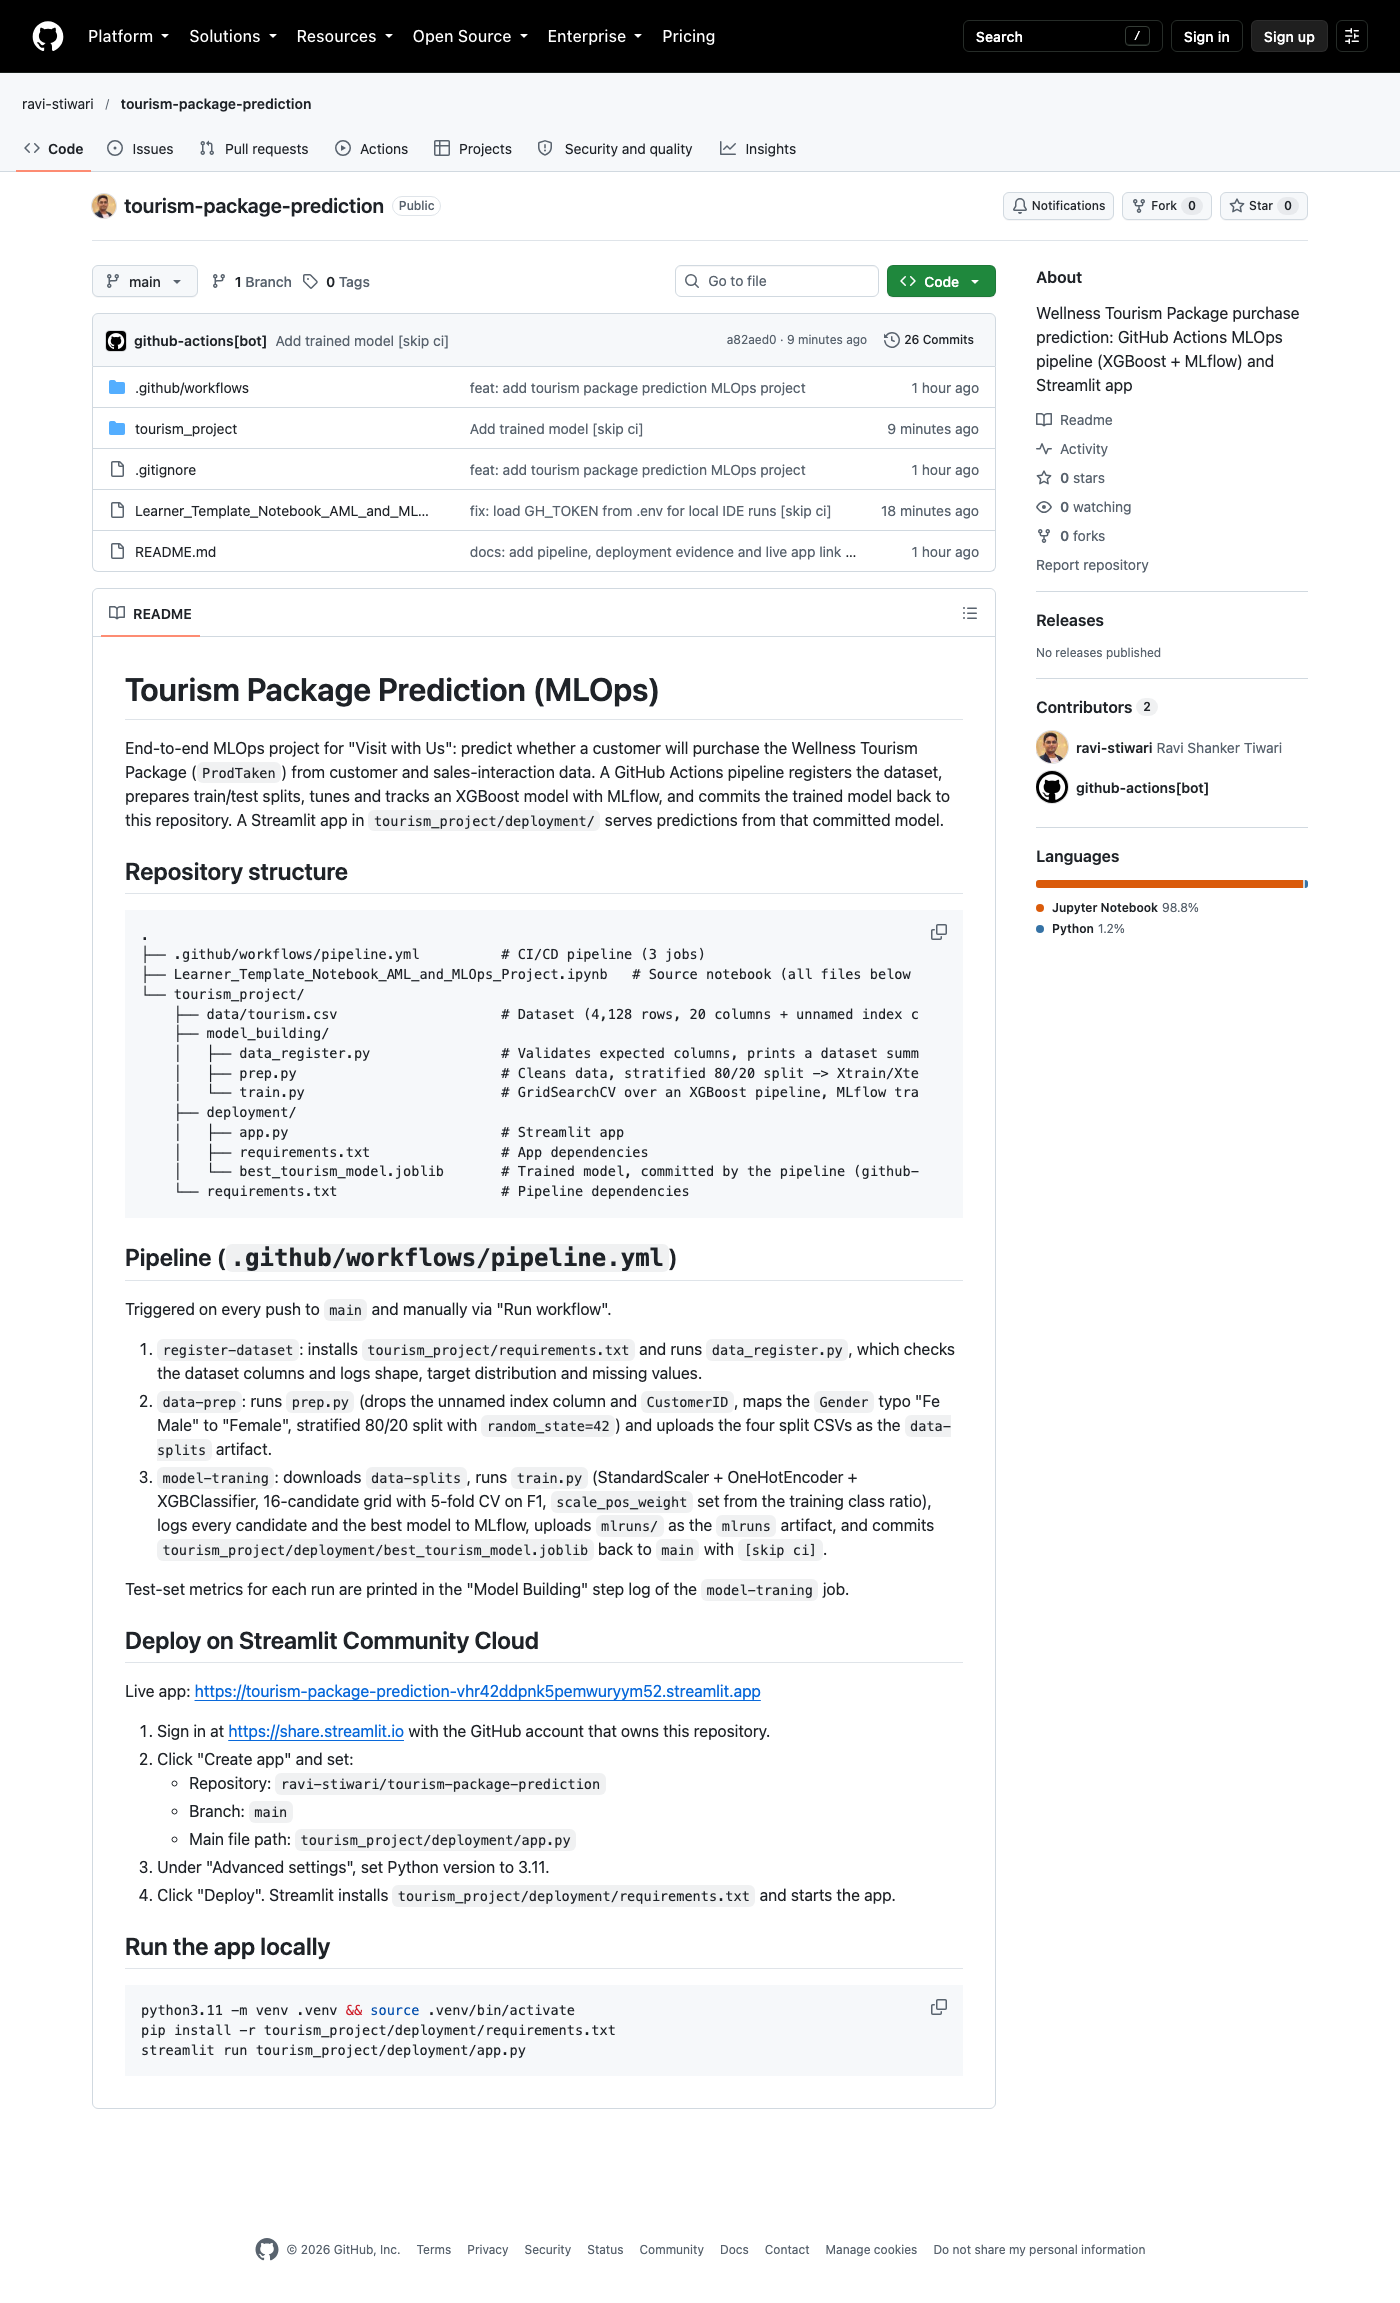

**`tourism_project/` folder structure:**

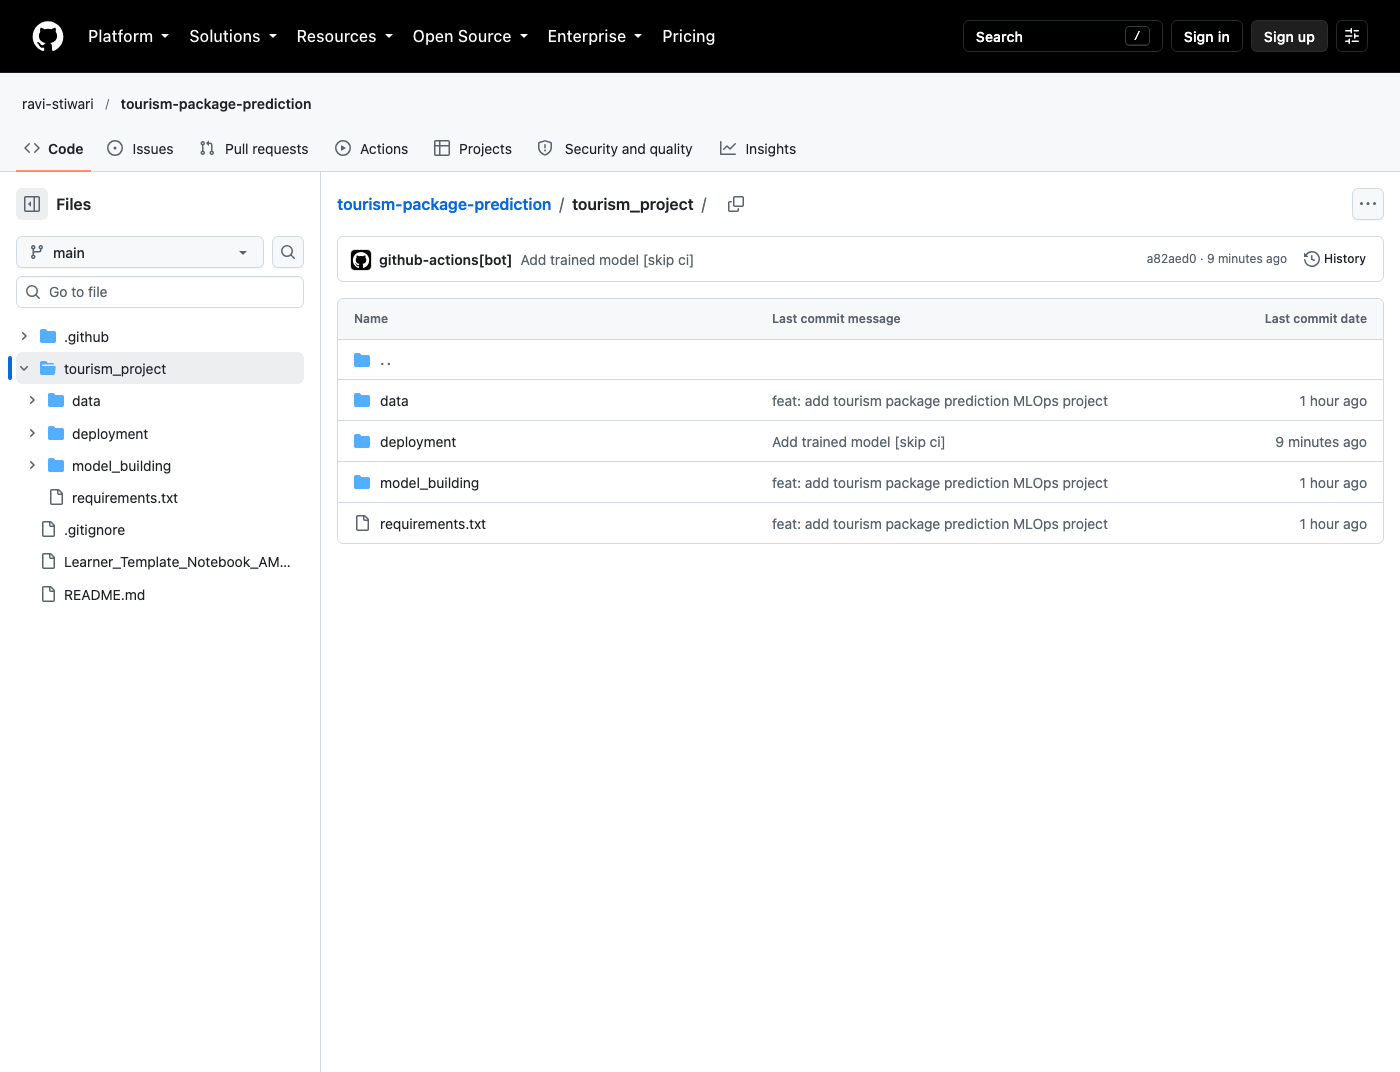

**Successful GitHub Actions run (3 green jobs):**

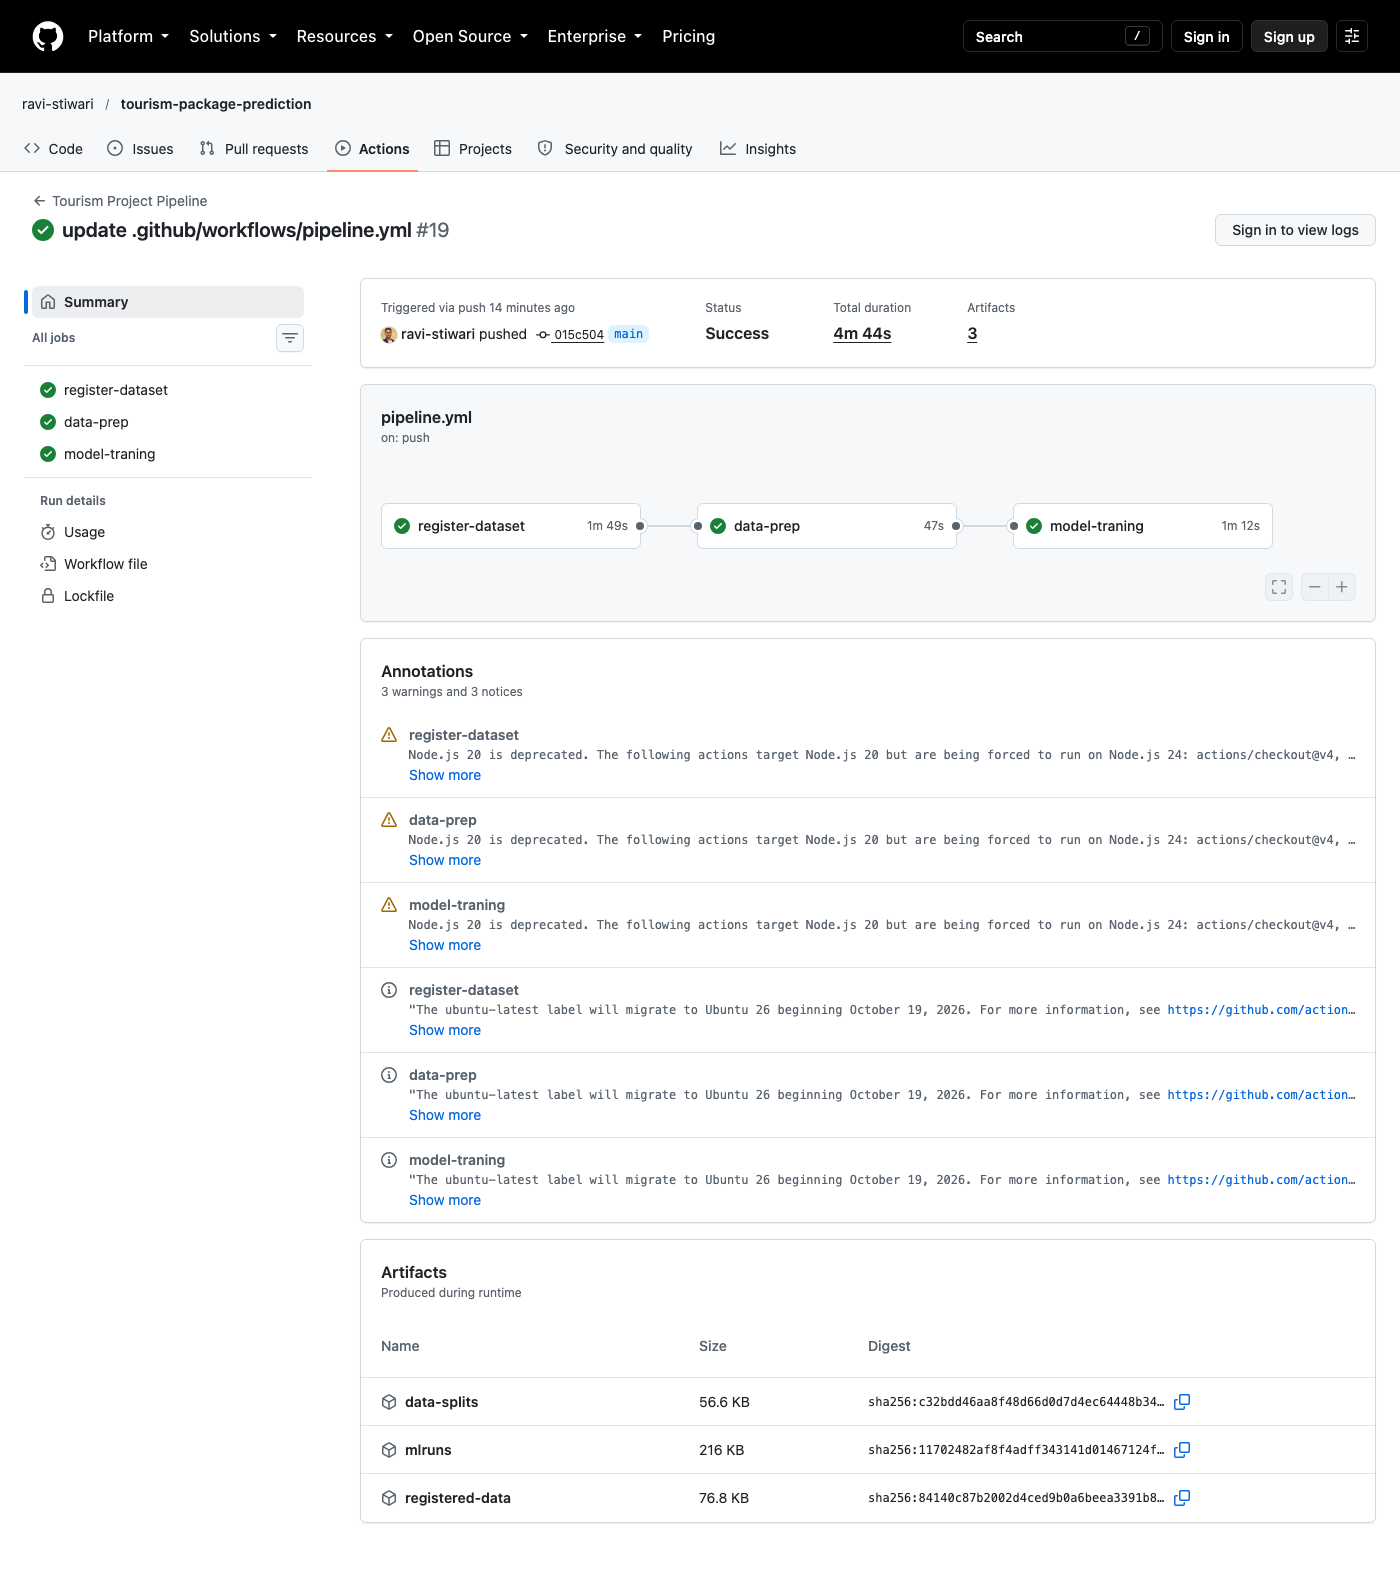

- Streamlit Community Cloud (link to the Streamlit app, screenshot of Streamlit app)

In [39]:
# Streamlit Community Cloud link and evidence
# -------------------------------------------
# Deployed from repo ravi-stiwari/tourism-package-prediction, branch main,
# main file tourism_project/deployment/app.py.
STREAMLIT_APP_URL = "https://tourism-package-prediction-vhr42ddpnk5pemwuryym52.streamlit.app"
print("Streamlit app:", STREAMLIT_APP_URL)

Streamlit app: https://tourism-package-prediction-vhr42ddpnk5pemwuryym52.streamlit.app


**Live Streamlit app with the default inputs after clicking Predict:**

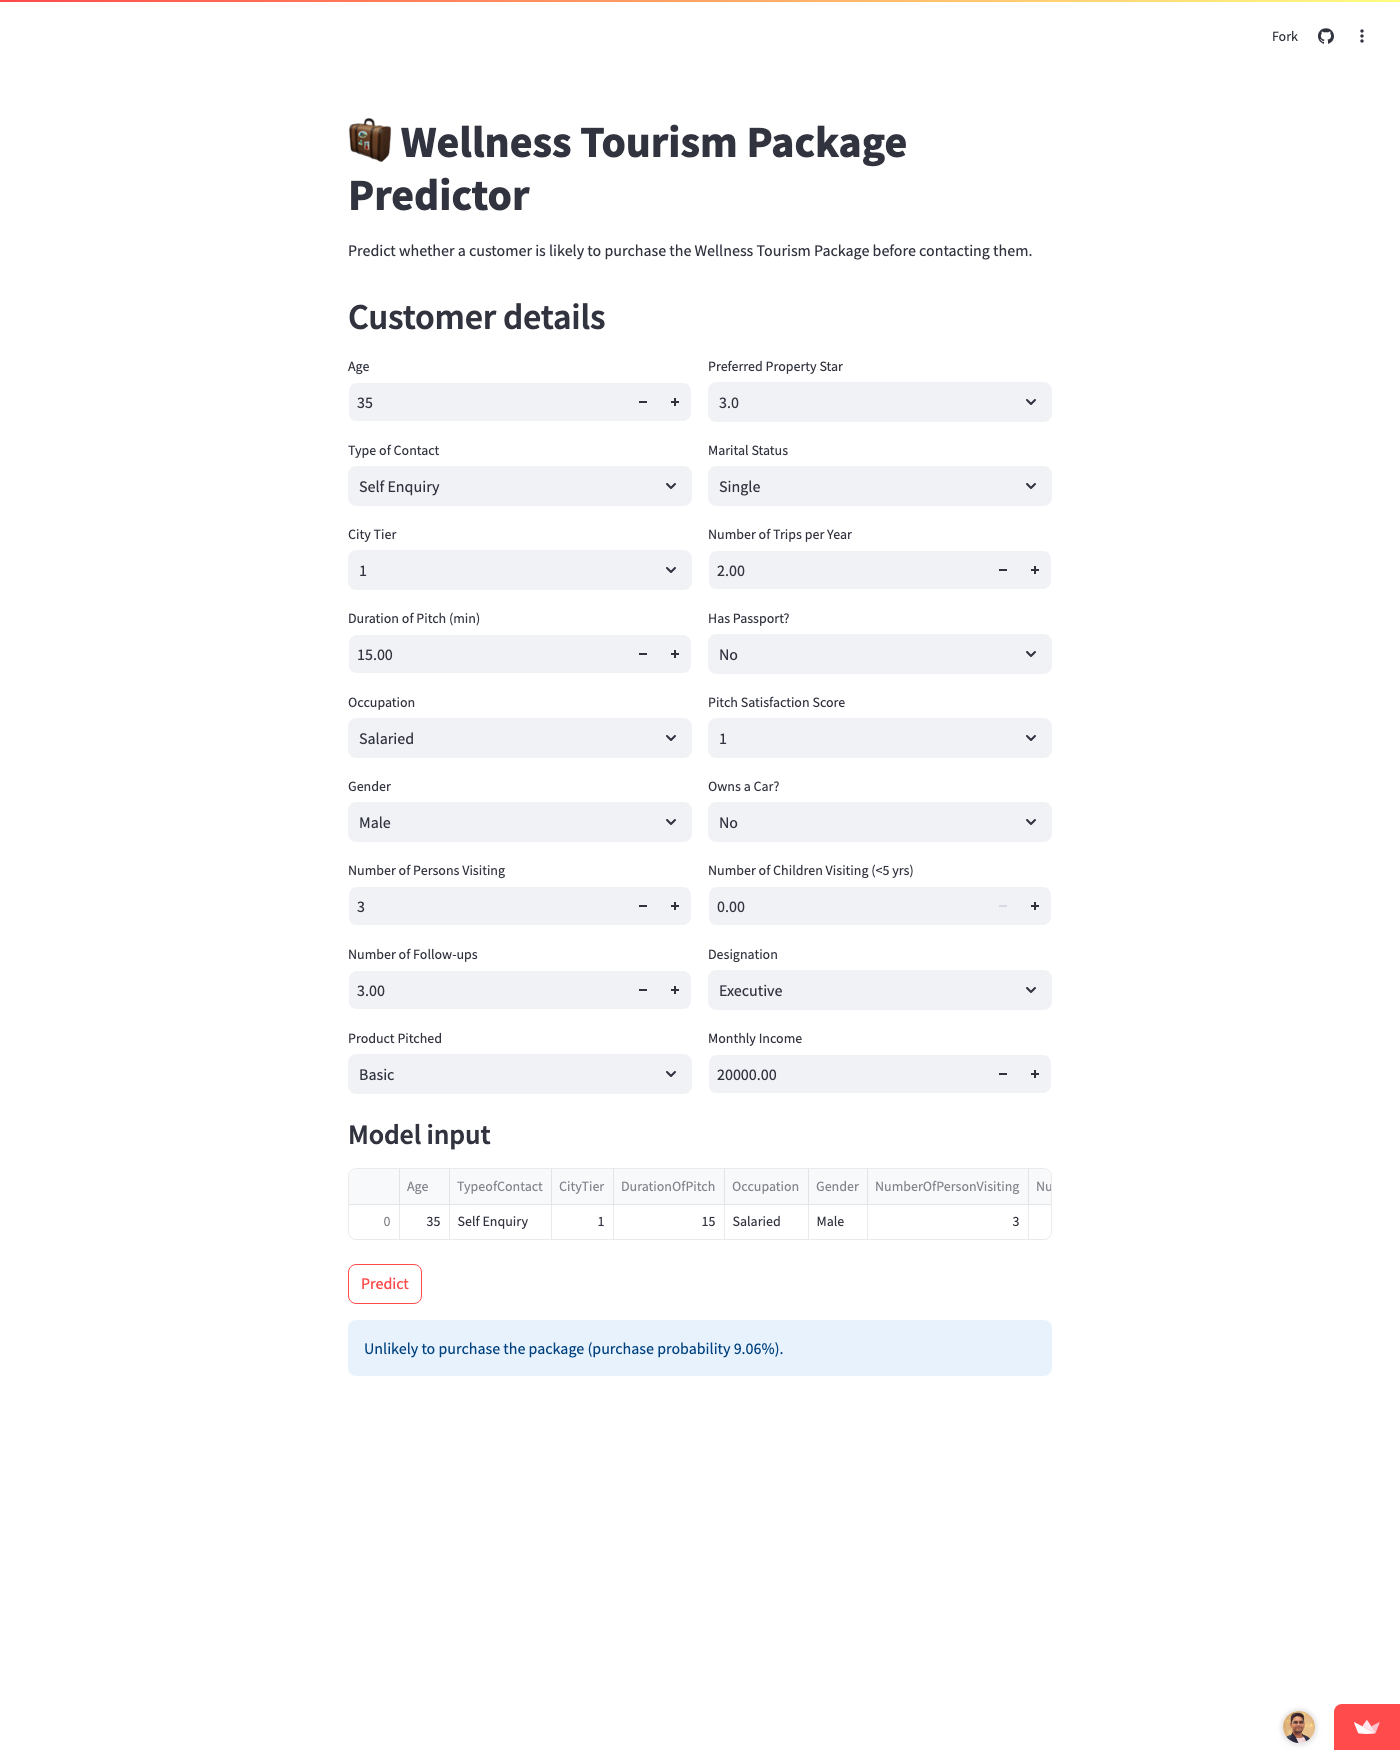

## Stop the MLflow UI (local run)
Locally, the MLflow UI started in the Experimentation and Tracking section runs as a background process on port 5001. The cell below stops it (the whole process group, so no server is left holding the port). In Colab the runtime is discarded with the session, so nothing is stopped there.

In [40]:
# Stop the background MLflow UI started earlier (local run only)
import signal

if not IN_COLAB and mlflow_ui.poll() is None:
    os.killpg(mlflow_ui.pid, signal.SIGTERM)  # mlflow_ui was started in its own session
    mlflow_ui.wait(timeout=30)
    print(f"MLflow UI on port {MLFLOW_PORT} stopped.")
else:
    print("Nothing to stop.")

MLflow UI on port 5001 stopped.


# Summary & Insights

**Data (from `tourism.csv`, 4,128 rows x 21 columns)**
- The target `ProdTaken` is imbalanced: 797 of 4,128 customers (19.3%) bought a package. This drove two modelling choices: `scale_pos_weight` = non-buyers/buyers in the training split (2,664/638 = 4.1755) and tuning on **F1** rather than accuracy.
- The dataset has 0 missing values, so the imputation step in `prep.py` is a safeguard only; it changed nothing here.
- Two columns carry no predictive signal and were dropped: the unnamed index column (always `CustomerID - 200000`) and `CustomerID` (unique per row).
- `Gender` contained a spelling variant `Fe Male` (155 rows) that was folded into `Female`. `MaritalStatus` was left as four categories (Married 1,990 / Divorced 789 / Unmarried 682 / Single 667): the data gives no basis to merge `Unmarried` into `Single`, and their purchase rates differ (24.3% vs 36.4%).

**Model (XGBoost pipeline, GridSearchCV, 16 candidates x 5 folds)**
- Best parameters: `learning_rate=0.1`, `max_depth=5`, `n_estimators=200`, `subsample=0.8`, `scale_pos_weight=4.1755`; best mean CV F1 0.7606 (std 0.0413).
- Held-out test set (826 rows, 159 buyers): accuracy **0.9116**, precision **0.7622**, recall **0.7862**, F1 **0.7740**, ROC-AUC **0.9501**. The GitHub Actions run reproduced these numbers exactly, so training is deterministic with the pinned versions.
- All 16 grid candidates are logged as nested MLflow runs (17 runs total including the parent), so every tuned parameter set and its CV score is traceable.

**MLOps pipeline**
- `pipeline.yml` runs three dependent jobs (register-dataset -> data-prep -> model-traning) on every push to `main`, passes the train/test splits and the `mlruns/` folder between jobs as workflow artifacts, and commits the retrained `best_tourism_model.joblib` back to the repository as `github-actions[bot]`. A concurrency group cancels superseded runs.
- The Streamlit app loads that committed model directly from the repo, collects the 18 model features into a single-row dataframe, and returns the purchase probability. It is live on Streamlit Community Cloud and the pipeline retrains the model whenever the code or data changes.

**Business takeaway**
- With a recall of 0.79 and precision of 0.76 on unseen customers, the model lets the sales team contact roughly four buyers for every five positive predictions while catching about four in five of the actual buyers, a large improvement over the manual, untargeted approach described in the problem statement.


<font size=6 color="navyblue">Power Ahead!</font>
___